In [ ]:
import os

from enphase_api.cloud.authentication import Authentication
from enphase_api.local.gateway import Gateway
from dotenv import load_dotenv
import json

load_dotenv('local.env')
ENPHASE_USERNAME = os.environ['ENPHASE_USERNAME']
ENPHASE_PASSWORD = os.environ['ENPHASE_PASSWORD']
IQ_GATEWAY_SERIAL_NUMBER = os.environ['IQ_GATEWAY_SERIAL_NUMBER']

In [ ]:
# Authenticate with Enphase®'s authentication server and get a token.
authentication = Authentication()
authentication.authenticate(ENPHASE_USERNAME, ENPHASE_PASSWORD)
token = authentication.get_token_for_commissioned_gateway(IQ_GATEWAY_SERIAL_NUMBER)

In [3]:
{'Content-Type': 'application/x-www-form-urlencoded', **authentication.HEADERS}

{'Content-Type': 'application/x-www-form-urlencoded',
 'User-Agent': '@@@SKIP_HEADER@@@',
 'Accept': 'application/json'}

In [4]:
{**authentication.HEADERS}

{'User-Agent': '@@@SKIP_HEADER@@@', 'Accept': 'application/json'}

In [14]:
Gateway.trust_gateway(IQ_GATEWAY_HOST)

In [16]:
gateway = Gateway(IQ_GATEWAY_HOST)

if gateway.login(token):
    response = gateway.api_call('/production.json')
    print(response)

{'production': [{'type': 'inverters', 'activeCount': 24, 'readingTime': 1763824581, 'wNow': 1428, 'whLifetime': 861288}, {'type': 'eim', 'activeCount': 1, 'measurementType': 'production', 'readingTime': 1763824870, 'wNow': 1761.717, 'whLifetime': 846229.411, 'varhLeadLifetime': 1058.226, 'varhLagLifetime': 238447.014, 'vahLifetime': 1062793.145, 'rmsCurrent': 14.938, 'rmsVoltage': 242.468, 'reactPwr': 268.48, 'apprntPwr': 1814.469, 'pwrFactor': 0.97, 'whToday': 969.411, 'whLastSevenDays': 141301.411, 'vahToday': 5001.145, 'varhLeadToday': 0.226, 'varhLagToday': 4285.014}], 'consumption': [{'type': 'eim', 'activeCount': 0, 'measurementType': 'total-consumption', 'readingTime': 1763824870, 'wNow': 1761.717, 'whLifetime': 846229.411, 'varhLeadLifetime': -1058.226, 'varhLagLifetime': -238447.014, 'vahLifetime': 0.0, 'rmsCurrent': 15.229, 'rmsVoltage': 242.57, 'reactPwr': 268.48, 'apprntPwr': 1847.111, 'pwrFactor': 0.95, 'whToday': 846229.411, 'whLastSevenDays': 846229.411, 'vahToday': 0.0,

In [ ]:
gateway.HEADERS

{'User-Agent': '@@@SKIP_HEADER@@@', 'Accept': 'application/json'}

In [17]:
response['production']

[{'type': 'inverters',
  'activeCount': 24,
  'readingTime': 1763824581,
  'wNow': 1428,
  'whLifetime': 861288},
 {'type': 'eim',
  'activeCount': 1,
  'measurementType': 'production',
  'readingTime': 1763824870,
  'wNow': 1761.717,
  'whLifetime': 846229.411,
  'varhLeadLifetime': 1058.226,
  'varhLagLifetime': 238447.014,
  'vahLifetime': 1062793.145,
  'rmsCurrent': 14.938,
  'rmsVoltage': 242.468,
  'reactPwr': 268.48,
  'apprntPwr': 1814.469,
  'pwrFactor': 0.97,
  'whToday': 969.411,
  'whLastSevenDays': 141301.411,
  'vahToday': 5001.145,
  'varhLeadToday': 0.226,
  'varhLagToday': 4285.014}]

In [18]:
gateway.host

'https://192.168.0.34'

In [35]:
gateway.api_call('/api/v1/production')

{'wattHoursToday': 1228,
 'wattHoursSevenDays': 141114,
 'wattHoursLifetime': 846488,
 'wattsNow': 2049}

In [34]:
gateway.api_call("/ivp/meters/reports")

[{'createdAt': 1763825704,
  'reportType': 'production',
  'cumulative': {'currW': 2252.873,
   'actPower': 2252.873,
   'apprntPwr': 2293.417,
   'reactPwr': 244.462,
   'whDlvdCum': 846662.881,
   'whRcvdCum': 0.002,
   'varhLagCum': 238510.118,
   'varhLeadCum': 1058.226,
   'vahCum': 1063238.417,
   'rmsVoltage': 241.967,
   'rmsCurrent': 18.933,
   'pwrFactor': 0.98,
   'freqHz': 60.0},
  'lines': [{'currW': 1126.58,
    'actPower': 1126.58,
    'apprntPwr': 1146.972,
    'reactPwr': 121.251,
    'whDlvdCum': 423438.431,
    'whRcvdCum': 0.001,
    'varhLagCum': 119358.234,
    'varhLeadCum': 608.13,
    'vahCum': 531865.387,
    'rmsVoltage': 121.02,
    'rmsCurrent': 9.465,
    'pwrFactor': 0.98,
    'freqHz': 60.0},
   {'currW': 1126.293,
    'actPower': 1126.293,
    'apprntPwr': 1146.445,
    'reactPwr': 123.211,
    'whDlvdCum': 423224.45,
    'whRcvdCum': 0.001,
    'varhLagCum': 119151.884,
    'varhLeadCum': 450.096,
    'vahCum': 531373.029,
    'rmsVoltage': 120.946,
  

In [22]:
import requests

In [23]:
headers = {"Accept": "application/json", "Authorization": f"Bearer {token}"}
url_base = "envoy.local"  # IQ_GATEWAYHOST
requests.post(f"https://{url_base}/auth/check_jwt", headers=headers)
# requests.get(f"https://{url_base}/info", headers=headers)

SSLError: HTTPSConnectionPool(host='envoy.local', port=443): Max retries exceeded with url: /auth/check_jwt (Caused by SSLError(SSLCertVerificationError(1, '[SSL: CERTIFICATE_VERIFY_FAILED] certificate verify failed: self-signed certificate (_ssl.c:1077)')))

In [27]:
import datetime    # We timestamp any errors.
import json        # This script makes heavy use of JSON parsing.
import os.path     # We check whether a file exists.
import sys         # We write to stderr.

import matplotlib.pyplot as plt          # Third party library; "pip install matplotlib"
import matplotlib.animation as animation # We use matplotlib animations for live data.
import matplotlib.dates                  # We use matplotlib date functions for comparisons.

import requests.exceptions               # We handle some of the exceptions we might get back.

# All the shared Enphase® functions are in these packages.
from enphase_api.cloud.authentication import Authentication
from enphase_api.local.gateway import Gateway

# Contains the axes (or chart).
axes = None

# The matplotlib figure.
figure = None

# The reference to the Gateway wrapper itself.
gateway = None

# Information about the meters (whether they are enabled etc.)
meters_status = None

# The lists which will hold the underlying raw data.
timestamp_data = []
production_data = []
consumption_net_data = []
consumption_total_data = []

# Reference to the plots and annotations.
production_plot = None
production_annotation = None
consumption_net_plot = None
consumption_net_annotation = None
consumption_total_plot = None
consumption_total_annotation = None

# Will map legend lines to artists.
legend_map = {}

# Store a count of the number of inverters for calculating system limits.
number_of_inverters = 0

def add_result_from_gateway():
    """
    Retrieves and processes energy production and consumption data from the Enphase® Gateway API.

    This function requests production and consumption data from the Enphase® Gateway API,
    processes the data, and updates global data lists for timestamps, production, and consumption.

    It handles cases where the API request fails due to connection issues or JSON decoding errors.

    Returns:
        bool: True if data was successfully added, False if an error occurred.
    """

    # Sometimes a request will intermittently fail and in this event we retry.
    try:
        # Get gateway production, consumption and storage status.
        production_statistics = gateway.api_call('/production.json')
    # Sometimes unable to connect (especially if using mDNS and it does not catch our query)
    except requests.exceptions.ConnectionError as exception:
        # Log this error.
        print(f'{datetime.datetime.now()} - Problem connecting..\n {exception}', file=sys.stderr)

        # No point continuing this function.
        return False
    except requests.exceptions.JSONDecodeError as exception:
        # Log this non-critial often transient error.
        print(f'{datetime.datetime.now()} - The Gateway returned bad JSON..\n {exception}', file=sys.stderr)

        # No point continuing this function.
        return False

    # Add the current date/time to the sample for the x-axis.
    timestamp_data.append(datetime.datetime.now())

    # Obtain the number of micro-inverters.
    production_statistics_production = [production_statistic for production_statistic in production_statistics['production'] if production_statistic['type'] == 'inverters'][0]
    global number_of_inverters
    number_of_inverters = production_statistics_production['activeCount']

    # The Production meters can be not present (not Gateway Metered) or individually turned off
    # (and they require a working CT clamp).
    meter_statistics_production = [meter_status for meter_status in meters_status if meter_status['measurementType'] == 'production'][0]
    if meter_statistics_production['state'] == 'enabled':
        # Get the Production section of the Production Statistics JSON that matches the configured
        # meter mode.
        production_statistics_production_eim = [production_statistic for production_statistic in production_statistics['production'] if production_statistic['type'] == 'eim' and production_statistic['measurementType'] == meter_statistics_production['measurementType']][0]

        # The current Production meter reading can read < 0 if energy (often a trace amount) is
        # actually flowing the other way from the grid.
        production_data.append(max(0, production_statistics_production_eim['wNow']) if production_statistics_production_eim['activeCount'] > 0 else 0)
    else:
        production_data.append(0)

    # The Consumption meters can be not present (not Gateway Metered) or individually turned off
    # (and they require a working CT clamp).
    meter_statistics_consumption = [meter_status for meter_status in meters_status if meter_status['measurementType'] == 'net-consumption' or meter_status['measurementType'] == 'total-consumption'][0]
    if meter_statistics_consumption['state'] == 'enabled':
        # Get the Consumption section for each meter of the Production Statistics JSON.
        for production_statistics_consumption in production_statistics['consumption']:

            if production_statistics_consumption['type'] == 'eim':
                # Which meter is this stats for?
                if production_statistics_consumption['measurementType'] == 'net-consumption':
                    # Net consumption statistics.
                    consumption_net_data.append(0-production_statistics_consumption['wNow'] if production_statistics_consumption['activeCount'] > 0 else 0)
                elif production_statistics_consumption['measurementType'] == 'total-consumption':
                    # Total consumption statistics.
                    consumption_total_data.append(0-production_statistics_consumption['wNow'] if production_statistics_consumption['activeCount'] > 0 else 0)
                else:
                    raise ValueError(f'Unknown measurementType : {production_statistics_consumption["measurementType"]}')
            else:
                print(f'Warning : Ignoring unknown consumption type: {production_statistics_consumption["type"]}')
    else:
        consumption_net_data.append(0)
        consumption_total_data.append(0)

    # We have updated data.
    return True

def on_pick(event):
    """
    Toggles the visibility of a plot and its associated annotation based on a legend line pick
    event.

    This function is called when a legend line is picked (clicked) on the plot. It toggles the
    visibility of the associated plot and its annotation. It also changes the alpha of the legend
    line to indicate whether the line is visible or hidden. Finally, it triggers a redraw of the
    chart.

    Args:
        event (PickEvent): The pick event triggered by clicking a legend line.

    Returns:
        None
    """

    # On the pick event, take the line in the legend.
    legend_line = event.artist

    # Toggle the mapped plot visibility (based off the plot's visibility).
    original_artist = legend_map[legend_line]
    visible = not original_artist[0].get_visible()

    # Set the visibility on the plot and annotation.
    _ = [artist.set_visible(visible) for artist in original_artist]

    # Change the alpha on the line in the legend, so we can see what lines have been toggled.
    legend_line.set_alpha(1.0 if visible else 0.2)

    # Redraw the chart.
    figure.canvas.draw()

def setup_plot():
    """
    Sets up the initial plot layout, including axes, legends, annotations, and plot data.

    This function configures the initial appearance of the plot, including creating the figure,
    connecting click events, setting axes labels and titles, plotting data, adding annotations,
    legends, and configuring grid lines.

    Returns:
        Figure: The created figure.
    """

    # The figure.
    figure = plt.figure('Enphase® Gateway Meters', figsize=(12,6), facecolor='#DEDEDE')

    # Allow the figure to be clickable.
    figure.canvas.mpl_connect('pick_event', on_pick)

    # The axes (or chart).
    global axes
    axes = figure.subplots()
    axes.set_facecolor('#DEDEDE')

    # Annotate the axes.
    axes.set_title('Enphase® Gateway Meters\n')
    axes.set_xlabel('Time')
    axes.set_ylabel('Watts')

    # Plot the data.
    global production_plot, consumption_total_plot, consumption_net_plot
    production_plot, = axes.plot(timestamp_data, production_data, c='#EC5E29', label='Production', marker='o', markevery=[-1])
    consumption_total_plot, = axes.plot(timestamp_data, consumption_total_data, c='#29B7EC', label='Consumption', marker='o', markevery=[-1])
    consumption_net_plot, = axes.plot(timestamp_data, consumption_net_data, c='#29EC5E', label='Export/Import', marker='o', markevery=[-1], visible=False)

    # Draw a horizontal line at 0 indicating import/export threshold.
    axes.axhline(linewidth=0.3, color='k')

    # Add the peak and continuous wattage limit lines of the IQ 7A micro-inverters.
    axes.axhline(y=number_of_inverters * 366, linewidth=1, color='r')
    axes.axhline(y=number_of_inverters * 349, linewidth=1, color='y')

    # Label the most recent result (at the end).
    global production_annotation, consumption_total_annotation, consumption_net_annotation
    production_annotation = axes.annotate(f'{production_data[-1]} W', xy=(timestamp_data[-1], production_data[-1]), xytext=(0, 5), textcoords='offset points')
    consumption_total_annotation = axes.annotate(f'{consumption_total_data[-1]} W', xy=(timestamp_data[-1], consumption_total_data[-1]), xytext=(0, 5), textcoords='offset points')
    consumption_net_annotation = axes.annotate(f'{consumption_net_data[-1]} W', xy=(timestamp_data[-1], consumption_net_data[-1]), xytext=(0, 5), textcoords='offset points', visible=False)

    # Display the legend.
    legend = axes.legend()

    for legend_line in legend.get_lines():
        # Change the alpha on the line in the legend, so we can see what lines have been toggled.
        legend_line.set_alpha(1.0 if legend_line.get_visible() else 0.2)

        # Make all the legend lines visible.
        legend_line.set_visible(True)

    # Make each of the series clickable in the legend and map them to their relevant artists.
    artists = [[production_plot, production_annotation], [consumption_total_plot, consumption_total_annotation], [consumption_net_plot, consumption_net_annotation]]

    for legend_line, original_artists in zip(legend.get_lines(), artists):
        # Enable picking on the legend line (with a 5px tolerance).
        legend_line.set_picker(5)

        # Hold a reference to each of the relevant artists for this legend line.
        legend_map[legend_line] = original_artists

    # Remove spines.
    axes.spines[['left','right','top']].set_visible(False)

    # Configure the axes' grid.
    axes.yaxis.grid(linestyle='dashed', alpha=0.8)

    # Return the figure.
    return figure

def update_axes():
    """
    Updates the plot data and annotations.

    This function updates the plot data based on the latest data in the global data lists.
    It also updates the annotations that display the most recent values on the plot.

    Returns:
        None
    """

    # Plot the data.
    production_plot.set_data(timestamp_data, production_data)
    consumption_total_plot.set_data(timestamp_data, consumption_total_data)
    consumption_net_plot.set_data(timestamp_data, consumption_net_data)

    # Update the annotations.
    production_annotation.xy = (timestamp_data[-1], production_data[-1])
    production_annotation.set_text(f'{production_data[-1]} W')

    consumption_total_annotation.xy = (timestamp_data[-1], consumption_total_data[-1])
    consumption_total_annotation.set_text(f'{consumption_total_data[-1]} W')

    consumption_net_annotation.xy = (timestamp_data[-1], consumption_net_data[-1])
    consumption_net_annotation.set_text(f'{consumption_net_data[-1]} W')

def animate(_):
    """
    Animates the chart by updating data, re-scaling, and refreshing the plot.

    This function is used by the animation to update the chart's data, re-scale the axes, and
    refresh the plot to reflect new data. It checks for new meter readings using
    'add_results_from_database()' and updates the axes if new data is found.

    It also manages the zoom behavior for the x-axis.

    Args:
        _: Dummy argument for the animation function.

    Returns:
        None
    """

    # Store this before it is potentially over-written.
    most_recent_timestamp = timestamp_data[-1]

    # If there are no new meter readings to add then we skip re-drawing.
    if add_result_from_gateway():
        # Update the axes.
        update_axes()

        # Get current zoom.
        old_x_lim = axes.get_xlim()
        old_y_lim = axes.get_ylim()

        # Check whether the current zoom included the old end datapoint
        # (i.e. user appeared deliberately interested in fresh data).
        user_viewing_recent_data = (old_x_lim[0] <= matplotlib.dates.date2num(most_recent_timestamp) <= old_x_lim[1])

        # Check whether the newest added data would now fall out of the old zoom view.
        new_data_visible_in_old_view = (old_x_lim[0] <= matplotlib.dates.date2num(timestamp_data[-1]) <= old_x_lim[1])

        # Ensure the axis are auto-scaled after adding new data.
        axes.relim()
        axes.autoscale()

        # Update the toolbar memory to the new zoomed out axis limits.
        figure.canvas.toolbar.update()
        figure.canvas.toolbar.push_current()

        # Was the user looking at old data before we added more data or were they looking at fresh
        # data that now will be outside of their view.
        if (not user_viewing_recent_data
                or (user_viewing_recent_data and new_data_visible_in_old_view)):
            # Restore old axis zoom (recent datapoint was never in zoom range anyway or zoom range
            # still covers the new data).
            axes.set_xlim(old_x_lim)
            axes.set_ylim(old_y_lim)

def get_secure_gateway_session(credentials):
    """
    Establishes a secure session with the Enphase® IQ Gateway API.

    This function manages the authentication process to establish a secure session with
    an Enphase® IQ Gateway.

    It handles JWT validation and initialises the Gateway API wrapper for subsequent interactions.

    It also downloads and stores the certificate from the gateway for secure communication.

    Args:
        credentials (dict): A dictionary containing the required credentials.

    Returns:
        Gateway: An initialised Gateway API wrapper object for interacting with the gateway.

    Raises:
        ValueError: If the token is missing/expired/invalid, or if there's an issue with login.
    """

    # Do we have a valid JSON Web Token (JWT) to be able to use the service?
    if not (credentials.get('gateway_token')
                and Authentication.check_token_valid(
                    token=credentials['gateway_token'],
                    gateway_serial_number=credentials.get('gateway_serial_number'))):
        # It is either not present or not valid.
        raise ValueError('No or expired token.')

    # Did the user override the library default hostname to the Gateway?
    host = credentials.get('gateway_host')

    # Download and store the certificate from the gateway so all future requests are secure.
    if not os.path.exists('configuration/gateway.cer'):
        Gateway.trust_gateway(host)

    # Instantiate the Gateway API wrapper (with the default library hostname if None provided).
    gateway = Gateway(host)

    # Are we not able to login to the gateway?
    if not gateway.login(credentials['gateway_token']):
        # Let the user know why the program is exiting.
        raise ValueError('Unable to login to the gateway (bad, expired or missing token in credentials_token.json).')

    # Return the initialised gateway object.
    return gateway

def main():
    """
    Main function for real-time plotting of Enphase® meter readings.

    This function loads credentials from a JSON file, initializes a secure session with the
    Enphase® Gateway API, retrieves meter status, collects the first result from the gateway, sets
    up a real-time plot, and displays the plot.

    Args:
        None

    Returns:
        None
    """

    # Load credentials.
    # with open('configuration/credentials_token.json', mode='r', encoding='utf-8') as json_file:
    #     credentials = json.load(json_file)
    credentials = {'gateway_token': token, 'gateway_serial_number': IQ_GATEWAY_SERIAL_NUMBER}

    # Use a secure gateway initialisation flow.
    global gateway
    gateway = get_secure_gateway_session(credentials)

    # The meter status tells us if they are enabled and what mode they are operating in
    # (production for production meters but net-consumption or total-consumption for consumption
    # meters).
    global meters_status
    meters_status = gateway.api_call('/ivp/meters')

    # Get the first result.
    add_result_from_gateway()

    # Draw the initial plot.
    global figure
    figure = setup_plot()

    # Set a timer to animate the chart every 1 second.
    _ = animation.FuncAnimation(figure, animate, interval=1000)

    # Show the plot screen.
    plt.show()

C:\Users\Brian\AppData\Local\Temp\ipykernel_44408\628739311.py:400: UserWarning: frames=None which we can infer the length of, did not pass an explicit *save_count* and passed cache_frame_data=True.  To avoid a possibly unbounded cache, frame data caching has been disabled. To suppress this warning either pass `cache_frame_data=False` or `save_count=MAX_FRAMES`.
  _ = animation.FuncAnimation(figure, animate, interval=1000)


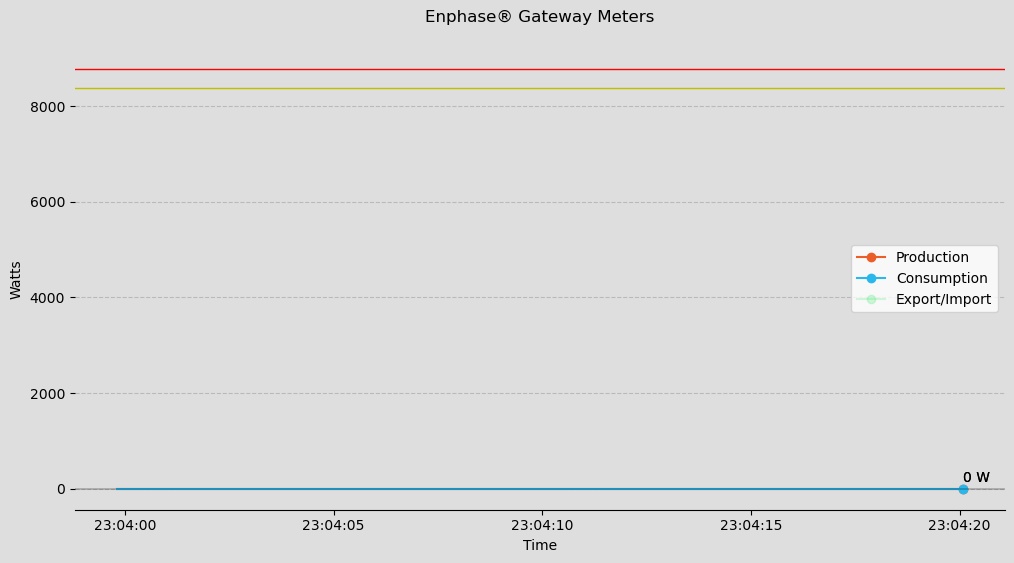

In [31]:
main()

In [2]:
from enphase_api.cloud.authentication_upython import Authentication

In [4]:
Authentication

enphase_api.cloud.authentication_upython.Authentication